# Check 7: Decision rate and sub-steps

In this model **one `model.step()` is one social decision for every fish**. `dt = 0.125 s` is the time between two decisions: 8 decisions per second, the "Direction update rate" in [Puckett et al. (2018), SI Table S1](https://static-content.springer.com/esm/art%3A10.1038%2Fs41598-018-26037-9/MediaObjects/41598_2018_26037_MOESM1_ESM.pdf). So `dt` is a behavioural parameter (a reaction time), not a numerical step that we should keep making smaller.

This notebook checks two things with the shared model in [`shiner_model.py`](../shiner_model.py):

1. **Decision count.** Every fish makes exactly 8 decisions per simulated second.
2. **Sub-steps.** An earlier notebook version split each 0.125-s interval into 8 movement sub-steps of 1/64 s and decided only on the first one. Between two decisions a fish swims in a straight line at constant speed, so 8 short moves should end where one long move ends. We test this, and show why the sub-steps were dropped.

`shiner_model.py` is not changed. Each test replaces one method for a moment and puts the original back afterwards. The full explanation is in [handlings/DECISION_RATE.md](../handlings/DECISION_RATE.md).

In [1]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root: start in the current folder and walk up
# until we reach the folder that contains shiner_model.py.
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "shiner_model.py").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("shiner_model.py was not found in this folder or any parent folder.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Let Python import files from the repository root.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shiner_model import GoldenShinersModel, GoldenShiners, reflect

# Settings used by every test in this notebook.
DECISION_INTERVAL = 0.125   # seconds between two social decisions (8 per second)
N_FISH = 20

# Show table numbers with 3 significant digits, for example 1.49e-13 or 26.5.
pd.set_option("display.float_format", "{:.3g}".format)

## 1. Count the decisions

A fish *decides* when it calls `social_direction()`: it looks at its neighbours and picks a new heading. To count these calls, we temporarily replace `GoldenShiners.social_direction` with a small wrapper. The wrapper adds 1 to that fish's counter and then calls the original method, so the fish behave exactly as before. The `finally` block puts the original method back, even if something goes wrong.

We run 10 simulated seconds with 20 fish. At 8 decisions per second, every fish should decide exactly **80** times.

In [2]:
# Remember the real method, so the wrapper can call it and we can put it back afterwards.
original_social_direction = GoldenShiners.social_direction

# decision_counts[fish ID] = how many decisions that fish has made
decision_counts = {}


def counting_social_direction(self, neighbors):
    """Count one decision for this fish, then make the normal social decision."""
    if self.unique_id not in decision_counts:
        decision_counts[self.unique_id] = 0
    decision_counts[self.unique_id] += 1
    return original_social_direction(self, neighbors)


SECONDS_TO_COUNT = 10
expected_decisions_per_fish = round(SECONDS_TO_COUNT / DECISION_INTERVAL)   # 10 / 0.125 = 80

# Run the standard model with the counting wrapper switched on.
GoldenShiners.social_direction = counting_social_direction
try:
    count_model = GoldenShinersModel(n_fish=N_FISH, seed=0)
    for _ in range(round(SECONDS_TO_COUNT / count_model.dt)):
        count_model.step()
finally:
    GoldenShiners.social_direction = original_social_direction

# The real method is back, the model used dt = 0.125 s,
# and every one of the 20 fish decided exactly 80 times.
assert GoldenShiners.social_direction is original_social_direction
assert count_model.dt == DECISION_INTERVAL
assert len(decision_counts) == N_FISH
for fish_id in decision_counts:
    assert decision_counts[fish_id] == expected_decisions_per_fish

pd.DataFrame([
    {"Quantity": "Simulated seconds", "Observed": count_model.steps * count_model.dt, "Expected": SECONDS_TO_COUNT},
    {"Quantity": "Steps (model.step() calls)", "Observed": count_model.steps, "Expected": expected_decisions_per_fish},
    {"Quantity": "Fish that made decisions", "Observed": len(decision_counts), "Expected": N_FISH},
    {"Quantity": "Fewest decisions made by one fish", "Observed": min(decision_counts.values()), "Expected": expected_decisions_per_fish},
    {"Quantity": "Most decisions made by one fish", "Observed": max(decision_counts.values()), "Expected": expected_decisions_per_fish},
])

,Quantity,Observed,Expected
0,Simulated seconds,10,10
1,Steps (model.step() calls),80,80
2,Fish that made decisions,20,20
3,Fewest decisions made by one fish,80,80
4,Most decisions made by one fish,80,80


**Interpretation.** Every fish made exactly one decision per step: 80 decisions in 80 steps, which is 8 per simulated second. The decision rate is tied to `dt`. Changing `dt` therefore changes how often the fish react to their neighbours, which is a change in behaviour, not only in numerical resolution. That is why `dt` stays at 0.125 s.

## 2. The sub-step version

To test the earlier sub-step idea, we run the **same shared model** with `dt = 0.125 / 8 = 1/64 s` and temporarily replace `GoldenShiners.decide` with `decide_with_substeps` below:

- On the first sub-step of every 0.125-s interval, the fish makes its normal social decision: `turn_toward(social_direction(get_neighbors()))`.
- On the other 7 sub-steps, it keeps its current heading `self.direction`, which already includes any wall bounce. It does not look at its neighbours.
- In both cases it moves and bounces off the walls with the same `reflect()` call as the real `decide()`.

Mesa adds 1 to `model.steps` just before `step()` runs, so the first step has `model.steps == 1`. That is why the test is `(model.steps - 1) % 8 == 0`: decisions happen on steps 1, 9, 17, …, which are the times 0, 0.125, 0.25, … s, just like the standard model.

The number 8 is not typed into the code: it is the named setting `SUBSTEPS_PER_DECISION`, and the sub-step `dt` is calculated from it.

In [3]:
SUBSTEPS_PER_DECISION = 8
SUBSTEP_DT = DECISION_INTERVAL / SUBSTEPS_PER_DECISION   # 0.125 / 8 = 1/64 s


def decide_with_substeps(self):
    """Replacement for GoldenShiners.decide(): a social decision only on the first sub-step."""
    # Is this the first sub-step of a 0.125-s decision interval?
    if (self.model.steps - 1) % SUBSTEPS_PER_DECISION == 0:
        # Yes: look at the neighbours and choose a new heading, exactly as decide() does.
        direction = self.turn_toward(self.social_direction(self.get_neighbors()))
    else:
        # No: keep the current heading. It already includes any wall bounce.
        direction = self.direction.copy()

    # Swim in a straight line and bounce off the walls, exactly as decide() does.
    position = self.position + direction * self.speed * self.model.dt
    self.next_position, self.next_direction = reflect(position, direction, self.model.bounds)

### Helpers to run and compare the models

- `fish_positions(model)` returns every fish's position, one row per fish, ordered by fish ID.
- `run_standard_model(...)` runs the normal model (`dt = 0.125 s`). With `nudge > 0`, every fish is first moved by that tiny distance in a random direction. This is the control run.
- `run_substep_model(...)` runs the sub-step version. It records one DataCollector row every 8 sub-steps (`record_every=8`), so both versions save the same rows.
- Both run functions save the fish positions at every decision time (every 0.125 s), so the runs can be compared at the same moments. They also return how long the `model.step()` calls took in total.
- `largest_distance_at_each_time(...)` gives, for each saved time, the largest distance between the same fish in two runs.
- `first_time_above(...)` gives the first time at which that distance goes above a threshold.

In [4]:
def fish_positions(model):
    """Return the positions of all fish (one row per fish), ordered by fish ID."""
    fish_by_id = sorted(model.agents, key=lambda fish: fish.unique_id)
    positions = []
    for fish in fish_by_id:
        positions.append(fish.position.copy())
    return np.array(positions)


def run_standard_model(seed, speed, seconds, nudge=0.0):
    """Run the normal model with dt = 0.125 s.

    Returns the fish positions at every decision time and the total time spent in model.step().
    """
    model = GoldenShinersModel(n_fish=N_FISH, speed=speed, seed=seed)

    # Control run only: move every fish by `nudge` in a random direction.
    # This uses its own random generator, so the model's random numbers are not touched.
    if nudge > 0:
        nudge_rng = np.random.default_rng(seed)
        for fish in model.agents:
            angle = nudge_rng.uniform(0, 2 * np.pi)
            fish.position = fish.position + nudge * np.array([np.cos(angle), np.sin(angle)])

    positions = [fish_positions(model)]
    runtime = 0.0
    for _ in range(round(seconds / model.dt)):
        start = time.perf_counter()
        model.step()
        runtime += time.perf_counter() - start
        positions.append(fish_positions(model))
    return np.array(positions), runtime


def run_substep_model(seed, speed, seconds):
    """Run the same shared model with 8 sub-steps of 1/64 s per decision.

    Returns the fish positions at every decision time and the total time spent in model.step().
    """
    # Switch on the sub-step version of decide(); the finally block always switches it off again.
    original_decide = GoldenShiners.decide
    GoldenShiners.decide = decide_with_substeps
    try:
        model = GoldenShinersModel(
            n_fish=N_FISH, speed=speed, seed=seed,
            dt=SUBSTEP_DT, record_every=SUBSTEPS_PER_DECISION,
        )
        positions = [fish_positions(model)]
        runtime = 0.0
        for substep in range(1, round(seconds / model.dt) + 1):
            start = time.perf_counter()
            model.step()
            runtime += time.perf_counter() - start
            # Save positions only at decision times, so they line up with the standard run.
            if substep % SUBSTEPS_PER_DECISION == 0:
                positions.append(fish_positions(model))
    finally:
        GoldenShiners.decide = original_decide
    return np.array(positions), runtime


def largest_distance_at_each_time(positions_a, positions_b):
    """For each saved time, the largest distance between the same fish in run A and run B."""
    differences = positions_a - positions_b             # shape: (times, fish, 2)
    distances = np.linalg.norm(differences, axis=2)     # shape: (times, fish)
    return distances.max(axis=1)                        # shape: (times,)


def first_time_above(distances, threshold):
    """First decision time (in seconds) at which the distance is above the threshold, or NaN if never."""
    for index in range(len(distances)):
        if distances[index] > threshold:
            return index * DECISION_INTERVAL
    return np.nan

### Check the sub-step version itself

Before comparing, we check the patch. With the counting wrapper from section 1 switched on, the sub-step version must still give **80 decisions per fish in 10 s**, now spread over 640 sub-steps. It must save 81 position snapshots (t = 0 plus one per 0.125 s), and both real methods must be back in place afterwards.

In [5]:
decision_counts = {}
GoldenShiners.social_direction = counting_social_direction
try:
    substep_positions, _ = run_substep_model(seed=0, speed=1.0, seconds=SECONDS_TO_COUNT)
finally:
    GoldenShiners.social_direction = original_social_direction

assert len(decision_counts) == N_FISH
for fish_id in decision_counts:
    assert decision_counts[fish_id] == expected_decisions_per_fish
assert len(substep_positions) == expected_decisions_per_fish + 1
assert GoldenShiners.social_direction is original_social_direction
assert GoldenShiners.decide is not decide_with_substeps

pd.DataFrame([
    {"Quantity": "Sub-steps of 1/64 s in 10 s", "Observed": round(SECONDS_TO_COUNT / SUBSTEP_DT), "Expected": 640},
    {"Quantity": "Fewest decisions made by one fish", "Observed": min(decision_counts.values()), "Expected": expected_decisions_per_fish},
    {"Quantity": "Most decisions made by one fish", "Observed": max(decision_counts.values()), "Expected": expected_decisions_per_fish},
    {"Quantity": "Saved position snapshots", "Observed": len(substep_positions), "Expected": expected_decisions_per_fish + 1},
])

,Quantity,Observed,Expected
0,Sub-steps of 1/64 s in 10 s,640,640
1,Fewest decisions made by one fish,80,80
2,Most decisions made by one fish,80,80
3,Saved position snapshots,81,81


## 3. Standard model, sub-step version and a nudged control

For seeds 0, 1 and 2 and speeds 1, 3 and 5 BL/s, we run 60 simulated seconds three times:

- **(a) standard:** the shared model with `dt = 0.125 s`;
- **(b) sub-steps:** the version from section 2, compared with (a) at every decision time;
- **(c) nudged control:** the standard model again, but every fish is moved by `1e-12` BL in a random direction right after construction.

At every decision time we measure the **largest distance between the same fish in two runs**, in body lengths (BL). The table shows:

- that distance for (b) vs (a) at 12.5, 30 and 60 s, and the largest value in the whole 60 s;
- the first time the distance goes above `1e-3` BL, for (b) vs (a) and for (c) vs (a). `NaN` means it never did within 60 s;
- how many times longer the `model.step()` calls took in (b) than in (a).

**Why the control?** If (b) were a different model, it would separate from (a) while (c) stays close. If instead the dynamics are chaotic, any tiny difference grows, whether it is a `1e-12` push or a rounding difference. In that case (b) and (c) separate from (a) at similar times.

In [6]:
SEEDS = [0, 1, 2]
SPEEDS = [1.0, 3.0, 5.0]
SECONDS_TO_COMPARE = 60
NUDGE = 1e-12        # body lengths
THRESHOLD = 1e-3     # body lengths
REPORT_TIMES = [12.5, 30, 60]

rows = []
distance_curves = {}   # (speed, seed) -> (distances b vs a, distances c vs a), used for the plot below

for speed in SPEEDS:
    for seed in SEEDS:
        # Run the three versions with the same seed and speed.
        positions_a, runtime_a = run_standard_model(seed, speed, SECONDS_TO_COMPARE)
        positions_b, runtime_b = run_substep_model(seed, speed, SECONDS_TO_COMPARE)
        positions_c, runtime_c = run_standard_model(seed, speed, SECONDS_TO_COMPARE, nudge=NUDGE)

        # Compare (b) and (c) with (a) at every decision time.
        b_vs_a = largest_distance_at_each_time(positions_b, positions_a)
        c_vs_a = largest_distance_at_each_time(positions_c, positions_a)
        distance_curves[(speed, seed)] = (b_vs_a, c_vs_a)

        # One table row per speed and seed.
        row = {"Speed (BL/s)": speed, "Seed": seed}
        for report_time in REPORT_TIMES:
            index = round(report_time / DECISION_INTERVAL)
            row[f"(b) vs (a) at {report_time:g} s"] = b_vs_a[index]
        row["(b) vs (a) largest in 60 s"] = b_vs_a.max()
        row["First > 1e-3, (b) vs (a) [s]"] = first_time_above(b_vs_a, THRESHOLD)
        row["First > 1e-3, (c) vs (a) [s]"] = first_time_above(c_vs_a, THRESHOLD)
        row["Runtime (b) / (a)"] = runtime_b / runtime_a
        rows.append(row)

results = pd.DataFrame(rows)
results

,Speed (BL/s),Seed,(b) vs (a) at 12.5 s,(b) vs (a) at 30 s,(b) vs (a) at 60 s,(b) vs (a) largest in 60 s,"First > 1e-3, (b) vs (a) [s]","First > 1e-3, (c) vs (a) [s]",Runtime (b) / (a)
0,1,0,1.49e-13,1.42e-12,1.63e-11,1.63e-11,NaN,NaN,2.51
1,1,1,1.38e-13,1.89e-12,1.44e-11,1.44e-11,NaN,NaN,2.54
2,1,2,6.82e-13,1.2e-12,2.06e-12,2.06e-12,NaN,NaN,2.57
3,3,0,1.05e-10,2.87,14.5,20.1,26.5,25.9,2.57
4,3,1,1.34e-05,11.8,12,20.6,14.4,11.9,2.54
5,3,2,1.61e-09,16.8,18,19.2,18.1,16,2.53
6,5,0,3.53,6.41,8.19,22.1,6.12,5.62,2.55
7,5,1,8.31,13.2,13.4,20.6,6.62,5.62,2.62
8,5,2,4.27,21.3,14.1,26.4,8,7.25,2.54


### Assert the speed-1 result

At 1 BL/s the sub-step version must stay within `1e-8` BL of the standard model for the whole 60 s, for every seed. The results at 3 and 5 BL/s are only reported, because chaos makes their exact times depend on rounding.

In [7]:
for seed in SEEDS:
    b_vs_a, c_vs_a = distance_curves[(1.0, seed)]
    largest = b_vs_a.max()
    assert largest < 1e-8, f"Seed {seed}: the sub-step run is {largest:.2e} BL away from the standard run."

print("Speed 1 BL/s: the sub-step version stays within 1e-8 BL of the standard model for 60 s (seeds 0, 1, 2).")

Speed 1 BL/s: the sub-step version stays within 1e-8 BL of the standard model for 60 s (seeds 0, 1, 2).


### Plot: how fast the runs move apart

Each panel is one speed. Blue solid lines are (b) vs (a), the sub-step version; orange dashed lines are (c) vs (a), the `1e-12` nudge. There is one line per seed. The y-axis is logarithmic, and the dotted grey line is the `1e-3` BL threshold. A log axis cannot show 0, so a distance of exactly 0 is drawn at `1e-16`.

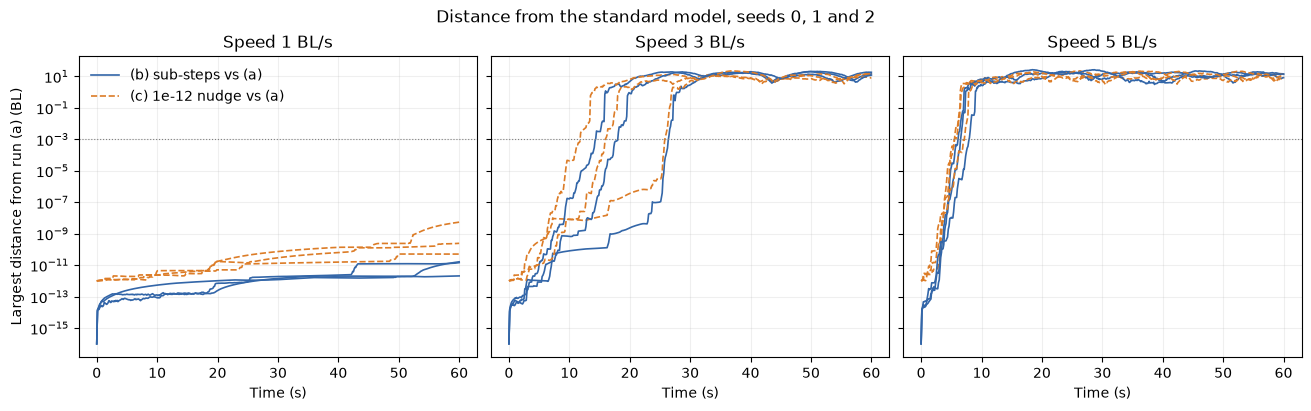

In [8]:
SUBSTEP_COLOR = "#3366a8"   # blue, from check 6
NUDGE_COLOR = "#dc7c27"     # orange, from check 6
SMALLEST_SHOWN = 1e-16      # a log axis cannot show 0

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, constrained_layout=True)

for panel in range(len(SPEEDS)):
    axis = axes[panel]
    speed = SPEEDS[panel]
    for seed in SEEDS:
        b_vs_a, c_vs_a = distance_curves[(speed, seed)]
        times = np.arange(len(b_vs_a)) * DECISION_INTERVAL
        # Only the first seed gets a legend label, so each run type appears once in the legend.
        if seed == SEEDS[0]:
            substep_label = "(b) sub-steps vs (a)"
            nudge_label = "(c) 1e-12 nudge vs (a)"
        else:
            substep_label = None
            nudge_label = None
        axis.plot(times, np.maximum(b_vs_a, SMALLEST_SHOWN), color=SUBSTEP_COLOR, linewidth=1.2, label=substep_label)
        axis.plot(times, np.maximum(c_vs_a, SMALLEST_SHOWN), color=NUDGE_COLOR, linewidth=1.2, linestyle="--", label=nudge_label)
    axis.axhline(THRESHOLD, color="0.5", linewidth=0.8, linestyle=":")
    axis.set_yscale("log")
    axis.set_title(f"Speed {speed:g} BL/s")
    axis.set_xlabel("Time (s)")
    axis.grid(alpha=0.2)

axes[0].set_ylabel("Largest distance from run (a) (BL)")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Distance from the standard model, seeds 0, 1 and 2")
plt.show()

## Conclusion

- **One decision per step.** Each fish makes exactly 8 decisions per simulated second (80 in 10 s). The sub-step version keeps the same 80 decisions, but needs 640 steps for them.
- **Speed 1 BL/s: same trajectories.** The sub-step version stays less than `2e-11` BL from the standard model for 60 s. Eight straight moves of 1/64 s end where one straight move of 0.125 s ends, so the sub-steps add nothing.
- **Speeds 3 and 5 BL/s: chaos, not a different model.** The sub-step runs separate from the standard runs after roughly 14–27 s at 3 BL/s and 6–8 s at 5 BL/s. The standard model separates *from itself* at similar times (12–26 s and 5.5–7.5 s) when every fish is moved by only `1e-12` BL. A rounding difference can move a neighbour in or out of a zone, and after that the paths separate.
- **Cost.** The sub-step version takes about 2.5× as long, even though here it searches for neighbours only at decisions. The notebook version in commits `7f795a8` and `a4eeddf` also searched at every sub-step, which made it 6–7× slower.

So the project keeps **one clock**: `dt = 0.125 s` is the decision interval. Smoother animations can interpolate between saved frames, because fish swim in straight lines between decisions. See [handlings/DECISION_RATE.md](../handlings/DECISION_RATE.md).